In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint

In [ ]:
UNIVERSE = [
    "BTC",
    "ETH",
    "SOL",
    "BNB",
    "XRP",
    "DOGE",
    "ADA",
    "LINK",
    "AVAX",
    "DOT",
    "LTC",
    "ATOM",
    "AAVE",
    "UNI",
    "ARB",
    "OP",
    "SUI",
    "NEAR",
    "ALGO",
    "FIL"
]

In [ ]:
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [ ]:
exchange = ccxt.kraken()
markets = exchange.load_markets()

symbols = []

for coin in UNIVERSE:
    c = f"{coin}/USD"
    if c in markets:
        symbols.append(c)

In [ ]:
pairs = list(combinations(symbols, 2))

In [ ]:
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close"]].copy()
    df = df.rename(columns={"close": symbol})
    return df

In [ ]:
def align_pair_prices(prices, asset_a, asset_b):
    """
    prices: wide DataFrame with columns ['timestamp', asset_a, asset_b, ...]
    returns: DataFrame with only the two assets aligned and sorted
    """
    out = prices[["timestamp", asset_a, asset_b]].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [ ]:
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Regress log(asset_a) on log(asset_b).
    Returns:
        df_out with log prices, spread, residuals
        alpha, beta, corr, pvalue
    """
    out = df.copy()

    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]

    model = sm.OLS(y, X).fit()

    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]

    out["spread"] = model.resid
    return out, alpha, beta, corr, model.pvalues[f"log_{asset_b}"]

In [ ]:
def spread_half_life(spread):
    """
    Estimate half-life from AR(1)-style mean reversion.
    """
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag

    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]

    if len(tmp) < 5:
        return np.nan

    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]

    if lam >= 0:
        return np.nan

    return -np.log(2) / lam

In [ ]:
def spread_crossings(z, threshold=2.0):
    """
    Count crossings of +/- threshold using one full-sample z-score series.
    """
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0

    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [ ]:
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    """
    One-row summary for pair selection.
    """
    df, alpha, beta, corr, pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "P_value": pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread Vol": spread_vol,
        "Half_life": hl,
        "Z_score Crossings": crossings
    })

In [ ]:
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [ ]:
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25):
    """
    Stateful position series:
      +1 = long spread
      -1 = short spread
       0 = flat
    """
    position = 0
    positions = []

    for val in z:
        if pd.isna(val):
            positions.append(0)
            continue

        if position == 0:
            if val < -entry_z:
                position = 1
            elif val > entry_z:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0

        elif position == -1:
            if val < exit_z:
                position = 0

        positions.append(position)

    return pd.Series(positions, index=z.index)

In [ ]:
def build_bollinger_positions(spread, window=25, band_k=1.0):
    """
    Stateful Bollinger-style spread strategy on the same spread.
    Enter on band break, exit when spread returns to rolling mean.
    """
    mid = spread.rolling(window).mean()
    std = spread.rolling(window).std()
    upper = mid + band_k * std
    lower = mid - band_k * std

    position = 0
    positions = []

    for s, m, u, l in zip(spread, mid, upper, lower):
        if pd.isna(s) or pd.isna(m) or pd.isna(u) or pd.isna(l):
            positions.append(0)
            continue

        if position == 0:
            if s < l:
                position = 1
            elif s > u:
                position = -1

        elif position == 1:
            if s >= m:
                position = 0

        elif position == -1:
            if s <= m:
                position = 0

        positions.append(position)

    out = pd.Series(positions, index=spread.index)
    return out, mid, upper, lower

In [ ]:
def backtest_pair_strategy(
    prices,
    asset_a,
    asset_b,
    strategy="zscore",
    beta=None,
    window=25,
    entry_z=2.0,
    exit_z=0.25,
    band_k=1.0,
    fee_bps=0.0
):
    """
    prices: wide DataFrame with timestamp, asset_a, asset_b
    strategy: 'zscore' or 'bollinger'

    Returns:
        bt_df: full backtest DataFrame
        metrics: one-row summary Series
    """
    df = align_pair_prices(prices, asset_a, asset_b)
    df, alpha_hat, beta_hat, corr, pvalue = estimate_ols_spread(df, asset_a, asset_b)

    if beta is None:
        beta = beta_hat

    # Core spread
    df["spread"] = df["spread"]
    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    if strategy == "zscore":
        df["zscore"] = rolling_zscore(df["spread"], window=window)
        df["position"] = build_zscore_positions(
            df["zscore"], entry_z=entry_z, exit_z=exit_z
        )

    elif strategy == "bollinger":
        df["position"], df["bb_mid"], df["bb_upper"], df["bb_lower"] = build_bollinger_positions(
            df["spread"], window=window, band_k=band_k
        )

    else:
        raise ValueError("strategy must be 'zscore' or 'bollinger'")

    # Legs
    # position = +1 long spread => long A, short beta * B
    # position = -1 short spread => short A, long beta * B
    # df["w_a"] = df["position"].astype(float)
    # df["w_b"] = -beta * df["position"].astype(float)

    gross = 1 + abs(beta)

    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    # Returns
    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    # Strategy return, shifted to avoid look-ahead
    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )

    # Optional transaction costs on turnover
    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )

    cost_per_turn = fee_bps / 10000.0
    costs = turnover * cost_per_turn

    df["strategy_ret"] = raw_ret - costs
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    # Metrics
    r = df["strategy_ret"].dropna()
    ann_factor = np.sqrt(24 * 365)

    sharpe = (r.mean() / r.std()) * ann_factor if r.std() != 0 else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1
    trades = (df["position"].diff().fillna(0) != 0).sum()

    # print(turnover.describe())

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Strategy": strategy,
        "Corr": corr,
        "P-value": pvalue,
        "Alpha": alpha_hat,
        "Beta": beta,
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Trades": int(trades),
        "Mean Hourly Return": r.mean(),
        "Vol Hourly": r.std()
    })

    return df, metrics

In [ ]:
def build_equal_vol_portfolio(ret_list):
    rets = pd.concat(ret_list, axis=1, join="inner").dropna()

    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()

    port_ret = rets.mul(weights, axis=1).sum(axis=1)
    port_eq = (1 + port_ret.fillna(0)).cumprod()

    sharpe = (port_ret.mean() / port_ret.std()) * np.sqrt(24 * 365) if port_ret.std() != 0 else np.nan
    max_dd = (port_eq / port_eq.cummax() - 1).min()
    cum_ret = port_eq.iloc[-1] - 1

    summary = pd.Series({
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Mean Hourly Return": port_ret.mean(),
        "Vol Hourly": port_ret.std(),
        "N Strategies": rets.shape[1]
    })

    return port_ret, port_eq, weights, summary

In [ ]:
prices = None

for coin in UNIVERSE:
    data = exchange.fetch_ohlcv(f"{coin}/USD", timeframe="1h", limit=1000)
    df = to_df(data, coin)

    if prices is None:
        prices = df
    else:
        prices = prices.merge(df, on="timestamp", how="inner")

In [ ]:
candidate_rows = []

for a, b in pairs:
    candidate_rows.append(pair_summary(prices, a.split("/")[0], b.split("/")[0]))

pair_table = pd.DataFrame(candidate_rows).sort_values("P_value")

result = pair_table.query('Corr > 0.8')
result = result.query('P_value < 0.05')
result = result.sort_values(by="Half_life")
result = result.sort_values(by="Z_score Crossings", ascending=False)

selected_pairs = result.reset_index().drop(columns=["index"])

In [ ]:
get_A = lambda x : x.split("/")[0]
get_B = lambda x : x.split("/")[1]

selected_pairs["Asset_A"] = selected_pairs["Pair"].apply(get_A)
selected_pairs["Asset_B"] = selected_pairs["Pair"].apply(get_B)

In [ ]:
selected_pairs.head()

,Pair,Asset_A,Asset_B,Corr,P_value,Alpha,Beta,Spread Vol,Half_life,Z_score Crossings
0,XRP/FIL,XRP,FIL,0.908655,6.343688e-275,0.314652,0.846059,0.013538,9.859288,17
1,DOGE/DOT,DOGE,DOT,0.946035,0.000000e+00,-2.455309,0.894694,0.015521,24.494978,17
2,DOT/ATOM,DOT,ATOM,0.904712,1.199404e-268,-0.534866,0.828668,0.021576,24.725475,12
3,BTC/LTC,BTC,LTC,0.847767,3.284686e-200,8.030059,0.797106,0.015066,40.562675,11
4,ETH/LTC,ETH,LTC,0.858479,1.051294e-210,1.259509,1.638759,0.029577,41.172466,10


In [ ]:
# all_results = []
# all_backtests = {}

# for _, row in selected_pairs.iterrows():
#     a = row["Asset_A"]
#     b = row["Asset_B"]

#     bt_z, m_z, r_z = backtest_pair_strategy(
#         prices=prices,
#         asset_a=a,
#         asset_b=b,
#         strategy="zscore",
#         beta=row.get("Beta", None),
#         window=25,
#         entry_z=2.0,
#         exit_z=0.25,
#         fee_bps=10.0
#     )

#     bt_bb, m_bb, r_bb = backtest_pair_strategy(
#         prices=prices,
#         asset_a=a,
#         asset_b=b,
#         strategy="bollinger",
#         beta=row.get("Beta", None),
#         window=25,
#         band_k=1.0,
#         fee_bps=10.0
#     )

#     all_backtests[(a, b, "zscore")] = bt_z
#     all_backtests[(a, b, "bollinger")] = bt_bb

#     all_results.append(m_z)
#     all_results.append(m_bb)
    
# results_df = pd.DataFrame(all_results).sort_values(["Pair", "Strategy"])
# results_df = results_df.set_index(["Pair", "Strategy"]).sort_index()
# results_df.head()

In [ ]:
# results_df.groupby("Strategy").mean(numeric_only=True)

In [ ]:
all_backtests = {}
all_results = []
z_returns = []
bb_returns = []

for _, row in selected_pairs.iterrows():
    a = row["Asset_A"]
    b = row["Asset_B"]

    bt_z, m_z = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="zscore",
        beta=row.get("Beta", None),
        window=25,
        entry_z=2.0,
        exit_z=0.25,
        fee_bps=7.0
    )

    bt_bb, m_bb = backtest_pair_strategy(
        prices=prices,
        asset_a=a,
        asset_b=b,
        strategy="bollinger",
        beta=row.get("Beta", None),
        window=25,
        band_k=1.0,
        fee_bps=7.0
    )

    all_backtests[(a, b, "zscore")] = bt_z
    all_backtests[(a, b, "bollinger")] = bt_bb

    z_returns.append(bt_z["strategy_ret"].rename(f"{a}/{b}"))
    bb_returns.append(bt_bb["strategy_ret"].rename(f"{a}/{b}"))


    all_results.append(m_z)
    all_results.append(m_bb)
    
results_df = pd.DataFrame(all_results).sort_values(["Pair", "Strategy"])
results_df = results_df.set_index(["Pair", "Strategy"]).sort_index()
results_df.head()

Corr        P-value     Alpha      Beta    Sharpe  \
Pair      Strategy                                                           
ADA/SUI   bollinger  0.829114  9.722414e-184 -1.230346  1.822448  3.883323   
          zscore     0.829114  9.722414e-184 -1.230346  1.822448  3.959274   
ATOM/ALGO bollinger  0.842082  5.791327e-195  3.205011  1.119333 -0.942296   
          zscore     0.842082  5.791327e-195  3.205011  1.119333 -1.080862   
BNB/FIL   bollinger  0.848155  1.415881e-200  6.481618  0.510873  1.551047   

                     Cumulative Return  Max Drawdown  Trades  \
Pair      Strategy                                             
ADA/SUI   bollinger           0.079039     -0.045323      95   
          zscore              0.061236     -0.033347      52   
ATOM/ALGO bollinger          -0.022173     -0.084383      84   
          zscore             -0.021098     -0.070757      42   
BNB/FIL   bollinger           0.019159     -0.028198      97   

                     Mean Hourly Return  Vol Hourly  
Pair      Strategy                                   
ADA/SUI   bollinger            0.000109    0.002630  
          zscore               0.000085    0.001999  
ATOM/ALGO bollinger           -0.000027    0.002725  
          zscore              -0.000027    0.002329  
BNB/FIL   bollinger            0.000028    0.001675

In [ ]:
z_port_ret, z_port_eq, z_weights, z_summary = build_equal_vol_portfolio(z_returns)
bb_port_ret, bb_port_eq, bb_weights, bb_summary = build_equal_vol_portfolio(bb_returns)

In [ ]:
portfolio_results_df = pd.DataFrame({
    "zscore": z_summary,
    "bollinger": bb_summary
}).T

portfolio_results_df

,Sharpe,Cumulative Return,Max Drawdown,Mean Hourly Return,Vol Hourly,N Strategies
zscore,3.327369,0.010604,-0.005282,0.000015,0.000414,28.0
bollinger,1.311000,0.005294,-0.010180,0.000007,0.000534,28.0


In [ ]:
# interpret means
# Bollinger generated more trades, but also larger drawdowns, suggesting it reacts to smaller spread deviations. 
# Z-score produced fewer but higher-quality trades, leading to better risk-adjusted performance.

In [ ]:
wide = results_df.unstack("Strategy")

In [ ]:
comparison = wide[[
    ("Sharpe", "zscore"),
    ("Sharpe", "bollinger"),
    ("Cumulative Return", "zscore"),
    ("Cumulative Return", "bollinger"),
    ("Max Drawdown", "zscore"),
    ("Max Drawdown", "bollinger"),
]].copy()

comparison.columns = [
    "Sharpe_Z",
    "Sharpe_BB",
    "Return_Z",
    "Return_BB",
    "DD_Z",
    "DD_BB",
]
comparison["Sharpe_diff"] = comparison["Sharpe_Z"] - comparison["Sharpe_BB"]
comparison["Return_diff"] = comparison["Return_Z"] - comparison["Return_BB"]
comparison["DD_diff"] = comparison["DD_Z"] - comparison["DD_BB"]

In [ ]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/SUI,2.959938,2.515824,0.044833,0.049314,-0.033638,-0.045870,0.444114,-0.004481,0.012233
ATOM/ALGO,-1.790975,-2.154130,-0.033340,-0.046485,-0.072704,-0.087119,0.363156,0.013145,0.014416
BNB/FIL,2.191771,-0.713235,0.021338,-0.010096,-0.022872,-0.028837,2.905006,0.031434,0.005965
BNB/XRP,-0.916317,-2.293941,-0.006998,-0.023124,-0.023788,-0.032124,1.377623,0.016126,0.008335
BTC/BNB,-3.008899,-4.865789,-0.016833,-0.035527,-0.023851,-0.038937,1.856890,0.018694,0.015086


In [ ]:
z_count = 0
b_count = 0

for _, row in comparison.iterrows():
    if row["Sharpe_diff"] > 0:
        z_count += 1
    else:
        b_count += 1


In [ ]:
print(z_count > b_count)

True


In [ ]:
bb_summary = results_df.xs('bollinger', level='Strategy')
z_summary = results_df.xs('zscore', level='Strategy')


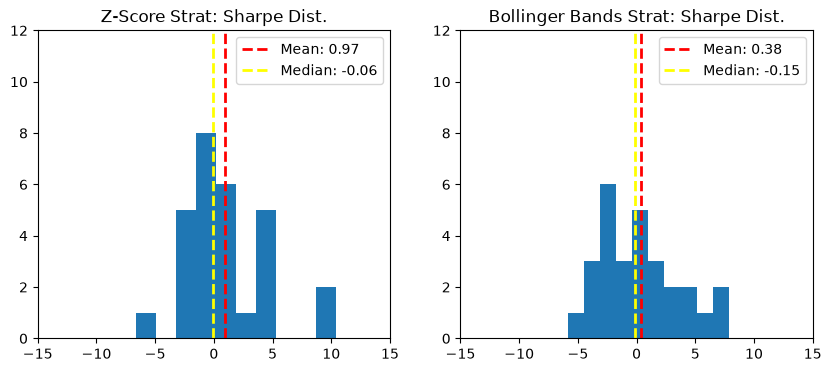

In [ ]:
fig1, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].hist(z_summary[["Sharpe"]])
zscore_mean = np.mean(z_summary[["Sharpe"]])
ax[0].axvline(zscore_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {zscore_mean:.2f}')
zscore_median = np.median(z_summary[["Sharpe"]])
ax[0].axvline(zscore_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {zscore_median:.2f}')

ax[1].hist(bb_summary[["Sharpe"]])
bb_mean = np.mean(bb_summary[["Sharpe"]])
ax[1].axvline(bb_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {bb_mean:.2f}')
bb_median = np.median(bb_summary[["Sharpe"]])
ax[1].axvline(bb_median, color='yellow', linestyle='dashed', linewidth=2, label=f'Median: {bb_median:.2f}')

ax[0].set_title("Z-Score Strat: Sharpe Dist.")
ax[1].set_title("Bollinger Bands Strat: Sharpe Dist.")

ax[0].set_xlim(-15, 15)
ax[0].set_ylim(0, 12)
ax[1].set_xlim(-15, 15)
ax[1].set_ylim(0, 12)

ax[0].legend()
ax[1].legend()

In [ ]:
results_df.index.get_level_values("Strategy").unique()

Index(['bollinger', 'zscore'], dtype='str', name='Strategy')

In [ ]:
color_map = {'zscore': 'yellow', 'bollinger': 'red'}
colors = [color_map[cat] for cat in results_df.index.get_level_values("Strategy")]

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_80357/759719422.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Risk to Return Comparison')

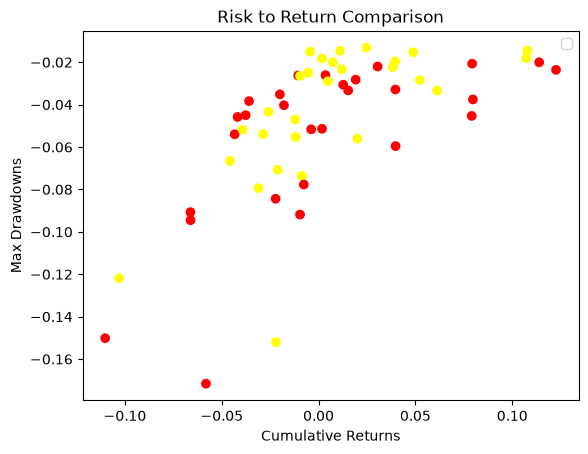

In [ ]:
plt.scatter(results_df[["Cumulative Return"]].values, results_df[["Max Drawdown"]].values, c=colors)
plt.xlabel("Cumulative Returns")
plt.ylabel("Max Drawdowns")
plt.legend()
plt.title("Risk to Return Comparison")

Text(0.5, 0.98, 'Distribution of Metrics Differences')

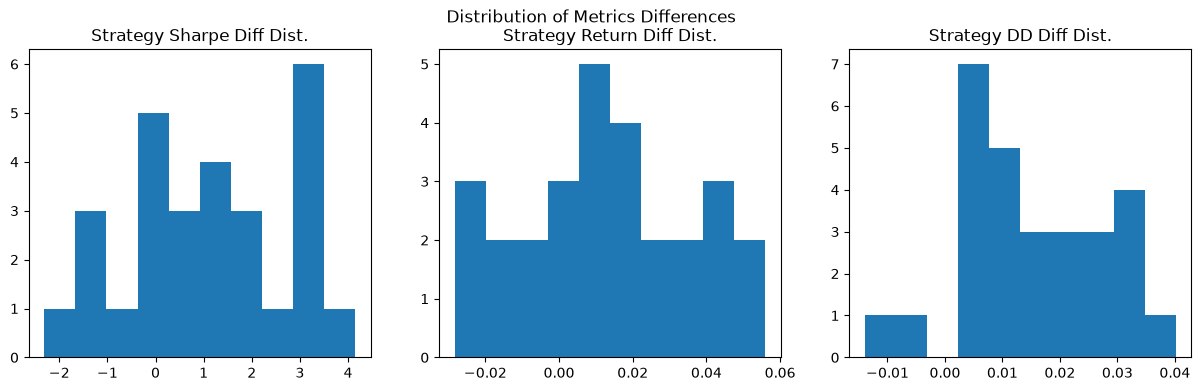

In [ ]:
fig3, ax3 = plt.subplots(1, 3, figsize=(15, 4))

ax3[0].hist(comparison[["Sharpe_diff"]])
ax3[1].hist(comparison[["Return_diff"]])
ax3[2].hist(comparison[["DD_diff"]])

ax3[0].set_title("Strategy Sharpe Diff Dist.")
ax3[1].set_title("Strategy Return Diff Dist.")
ax3[2].set_title("Strategy DD Diff Dist.")

fig3.suptitle("Distribution of Metrics Differences")

Text(0.5, 0.98, 'Performance Metrics Comparison')

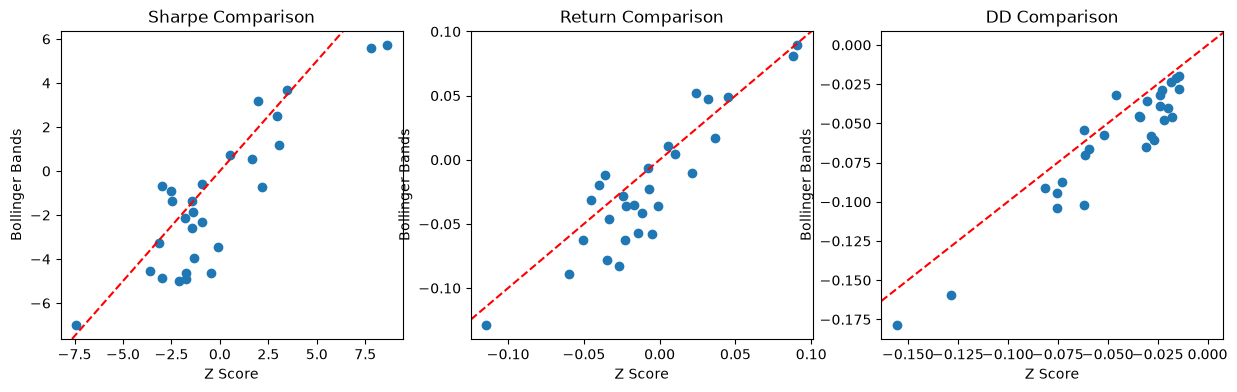

In [ ]:
fig4, ax4 = plt.subplots(1, 3, figsize=(15, 4))

ax4[0].scatter(comparison[["Sharpe_Z"]], comparison[["Sharpe_BB"]])
ax4[1].scatter(comparison[["Return_Z"]], comparison[["Return_BB"]])
ax4[2].scatter(comparison[["DD_Z"]], comparison[["DD_BB"]])

ax4[0].set_title("Sharpe Comparison")
ax4[1].set_title("Return Comparison")
ax4[2].set_title("DD Comparison")

ax4[0].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[1].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")
ax4[2].axline((0, 0), slope=1, color="red", linestyle="--", label="1:1 Line")

ax4[0].set_xlabel("Z Score")
ax4[1].set_xlabel("Z Score")
ax4[2].set_xlabel("Z Score")

ax4[0].set_ylabel("Bollinger Bands")
ax4[1].set_ylabel("Bollinger Bands")
ax4[2].set_ylabel("Bollinger Bands")

fig3.suptitle("Performance Metrics Comparison")

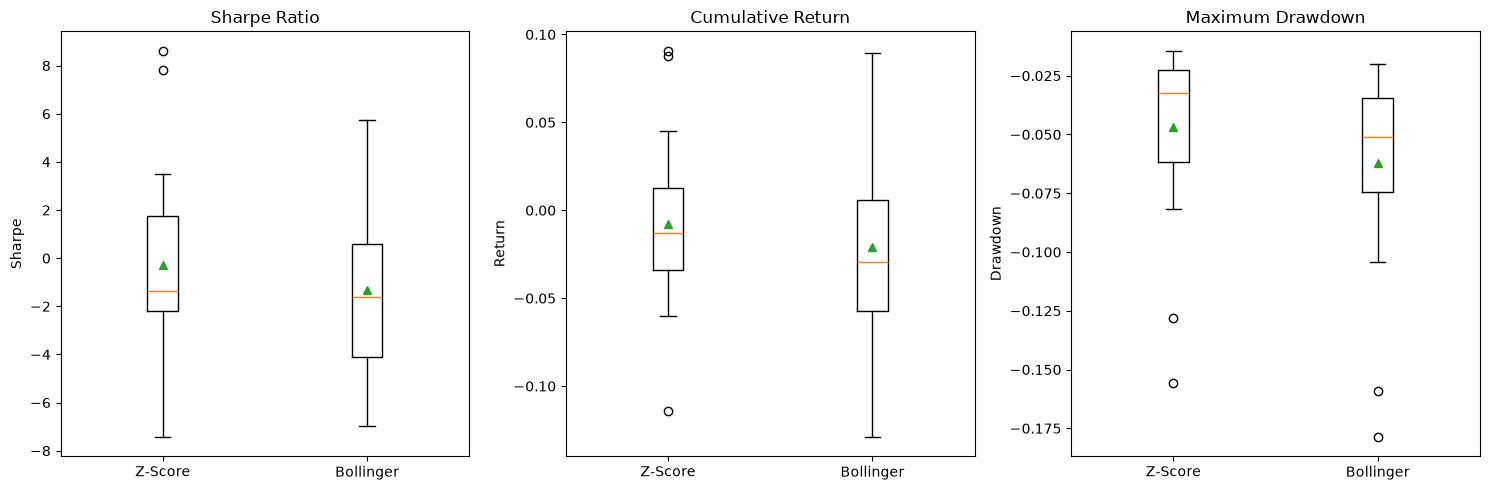

In [ ]:
fig5, ax5 = plt.subplots(1, 3, figsize=(15, 5))

# -----------------------
# Sharpe
# -----------------------
ax5[0].boxplot(
    [comparison["Sharpe_Z"], comparison["Sharpe_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[0].set_title("Sharpe Ratio")
ax5[0].set_ylabel("Sharpe")

# -----------------------
# Cumulative Return
# -----------------------
ax5[1].boxplot(
    [comparison["Return_Z"], comparison["Return_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[1].set_title("Cumulative Return")
ax5[1].set_ylabel("Return")

# -----------------------
# Max Drawdown
# -----------------------
ax5[2].boxplot(
    [comparison["DD_Z"], comparison["DD_BB"]],
    tick_labels=["Z-Score", "Bollinger"],
    showmeans=True
)
ax5[2].set_title("Maximum Drawdown")
ax5[2].set_ylabel("Drawdown")

plt.tight_layout()
plt.show()

In [ ]:
comparison.head()

,Sharpe_Z,Sharpe_BB,Return_Z,Return_BB,DD_Z,DD_BB,Sharpe_diff,Return_diff,DD_diff
Pair,,,,,,,,,
ADA/SUI,2.959938,2.515824,0.044833,0.049314,-0.033638,-0.045870,0.444114,-0.004481,0.012233
ATOM/ALGO,-1.790975,-2.154130,-0.033340,-0.046485,-0.072704,-0.087119,0.363156,0.013145,0.014416
BNB/FIL,2.191771,-0.713235,0.021338,-0.010096,-0.022872,-0.028837,2.905006,0.031434,0.005965
BNB/XRP,-0.916317,-2.293941,-0.006998,-0.023124,-0.023788,-0.032124,1.377623,0.016126,0.008335
BTC/BNB,-3.008899,-4.865789,-0.016833,-0.035527,-0.023851,-0.038937,1.856890,0.018694,0.015086


In [ ]:
from scipy.stats import ttest_rel
ttest_rel(comparison["Sharpe_Z"], comparison["Sharpe_BB"])

TtestResult(statistic=np.float64(3.2715789904594406), pvalue=np.float64(0.0029232009395163375), df=np.int64(27))

In [ ]:
ttest_rel(comparison["Return_Z"], comparison["Return_BB"])


TtestResult(statistic=np.float64(3.0438176123203777), pvalue=np.float64(0.005159086226749495), df=np.int64(27))

In [ ]:
ttest_rel(comparison["DD_Z"], comparison["DD_BB"])

TtestResult(statistic=np.float64(6.260682600409686), pvalue=np.float64(1.0675801826542684e-06), df=np.int64(27))

In [ ]:
results_df.sort_values(by="Sharpe", ascending=False)

Corr        P-value      Alpha      Beta    Sharpe  \
Pair     Strategy                                                            
XRP/FIL  zscore     0.893393  4.785637e-252   0.328580  0.893300  9.818767   
BTC/FIL  zscore     0.883809  2.151664e-239  11.229429  0.716731  9.527170   
LINK/FIL zscore     0.818204  5.278923e-175   2.321425  1.030716  6.415547   
XRP/FIL  bollinger  0.893393  4.785637e-252   0.328580  0.893300  6.178605   
BTC/FIL  bollinger  0.883809  2.151664e-239  11.229429  0.716731  6.035731   
...                      ...            ...        ...       ...       ...   
BTC/XRP  zscore     0.808761  6.620233e-168  10.979611  0.655938 -4.130350   
         bollinger  0.808761  6.620233e-168  10.979611  0.655938 -4.253790   
ETH/UNI  bollinger  0.873061  1.809157e-226   6.805723  0.556757 -4.481686   
SOL/AVAX zscore     0.807359  6.926772e-167   2.028720  1.219650 -4.657387   
BTC/BNB  bollinger  0.887585  3.049177e-244   3.862541  1.130810 -4.858817   

                    Cumulative Return  Max Drawdown  Trades  \
Pair     Strategy                                             
XRP/FIL  zscore              0.125060     -0.017708      56   
BTC/FIL  zscore              0.098887     -0.009468      60   
LINK/FIL zscore              0.087482     -0.016961      59   
XRP/FIL  bollinger           0.109181     -0.024264     104   
BTC/FIL  bollinger           0.087509     -0.020452     100   
...                               ...           ...     ...   
BTC/XRP  zscore             -0.030333     -0.036417      40   
         bollinger          -0.039106     -0.055521      73   
ETH/UNI  bollinger          -0.082296     -0.101321      59   
SOL/AVAX zscore             -0.074666     -0.089801      38   
BTC/BNB  bollinger          -0.035335     -0.037473      89   

                    Mean Hourly Return  Vol Hourly  
Pair     Strategy                                   
XRP/FIL  zscore               0.000165    0.001572  
BTC/FIL  zscore               0.000132    0.001295  
LINK/FIL zscore               0.000118    0.001721  
XRP/FIL  bollinger            0.000146    0.002217  
BTC/FIL  bollinger            0.000118    0.001833  
...                                ...         ...  
BTC/XRP  zscore              -0.000042    0.000959  
         bollinger           -0.000055    0.001203  
ETH/UNI  bollinger           -0.000116    0.002429  
SOL/AVAX zscore              -0.000106    0.002121  
BTC/BNB  bollinger           -0.000050    0.000954  

[62 rows x 10 columns]

In [ ]:
results_df.sort_values(by="Cumulative Return", ascending=False)

Corr        P-value      Alpha      Beta    Sharpe  \
Pair     Strategy                                                            
XRP/FIL  zscore     0.893393  4.785637e-252   0.328580  0.893300  9.818767   
         bollinger  0.893393  4.785637e-252   0.328580  0.893300  6.178605   
BTC/FIL  zscore     0.883809  2.151664e-239  11.229429  0.716731  9.527170   
         bollinger  0.883809  2.151664e-239  11.229429  0.716731  6.035731   
LINK/FIL zscore     0.818204  5.278923e-175   2.321425  1.030716  6.415547   
...                      ...            ...        ...       ...       ...   
SOL/AVAX bollinger  0.807359  6.926772e-167   2.028720  1.219650 -3.580029   
UNI/ARB  bollinger  0.832267  2.225492e-186   3.481472  0.930271 -2.335740   
SOL/AVAX zscore     0.807359  6.926772e-167   2.028720  1.219650 -4.657387   
DOT/ALGO bollinger  0.855649  7.519061e-208   2.379170  1.033699 -3.863911   
ETH/UNI  bollinger  0.873061  1.809157e-226   6.805723  0.556757 -4.481686   

                    Cumulative Return  Max Drawdown  Trades  \
Pair     Strategy                                             
XRP/FIL  zscore              0.125060     -0.017708      56   
         bollinger           0.109181     -0.024264     104   
BTC/FIL  zscore              0.098887     -0.009468      60   
         bollinger           0.087509     -0.020452     100   
LINK/FIL zscore              0.087482     -0.016961      59   
...                               ...           ...     ...   
SOL/AVAX bollinger          -0.069772     -0.090088      74   
UNI/ARB  bollinger          -0.071433     -0.182971      69   
SOL/AVAX zscore             -0.074666     -0.089801      38   
DOT/ALGO bollinger          -0.078729     -0.109270      80   
ETH/UNI  bollinger          -0.082296     -0.101321      59   

                    Mean Hourly Return  Vol Hourly  
Pair     Strategy                                   
XRP/FIL  zscore               0.000165    0.001572  
         bollinger            0.000146    0.002217  
BTC/FIL  zscore               0.000132    0.001295  
         bollinger            0.000118    0.001833  
LINK/FIL zscore               0.000118    0.001721  
...                                ...         ...  
SOL/AVAX bollinger           -0.000097    0.002542  
UNI/ARB  bollinger           -0.000096    0.003830  
SOL/AVAX zscore              -0.000106    0.002121  
DOT/ALGO bollinger           -0.000110    0.002672  
ETH/UNI  bollinger           -0.000116    0.002429  

[62 rows x 10 columns]

Text(0.5, 1.0, 'Equal Volatility Portfolio')

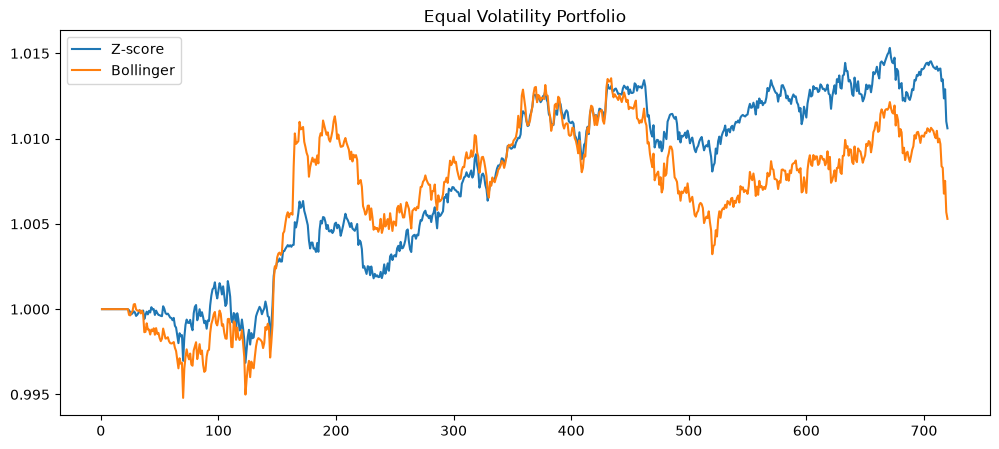

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(z_port_eq, label="Z-score")
plt.plot(bb_port_eq, label="Bollinger")
plt.legend()
plt.title("Equal Volatility Portfolio")

In [ ]:
z_drawdown = z_port_eq / z_port_eq.cummax() - 1
bb_drawdown = bb_port_eq / bb_port_eq.cummax() - 1

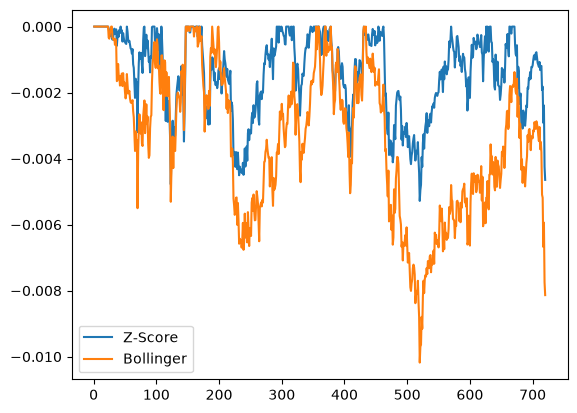

In [ ]:
plt.plot(z_drawdown, label='Z-Score')
plt.plot(bb_drawdown, label="Bollinger")
plt.legend()

In [ ]:
ann_factor = np.sqrt(24 * 365)

expanding_sharpe_z = (
    z_port_ret.expanding(min_periods=100).mean() /
    z_port_ret.expanding(min_periods=100).std()
) * ann_factor

expanding_sharpe_bb = (
    bb_port_ret.expanding(min_periods=100).mean() /
    bb_port_ret.expanding(min_periods=100).std()
) * ann_factor

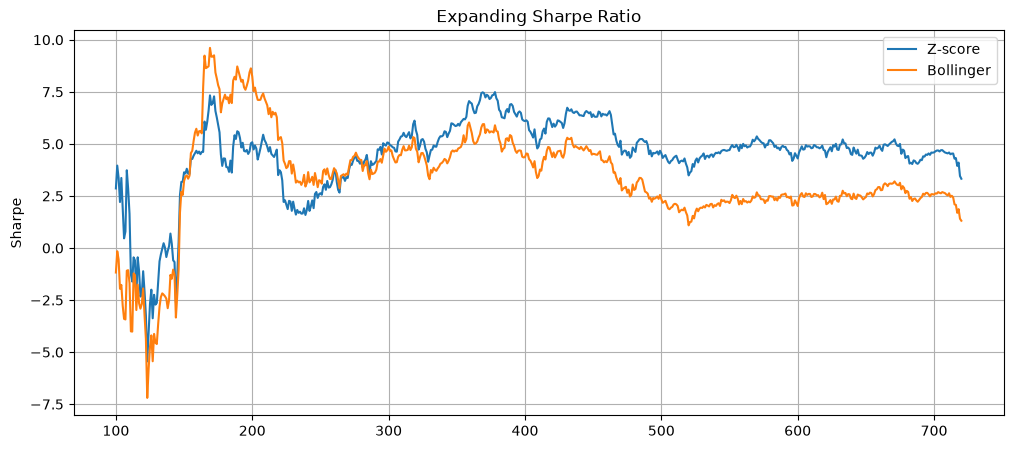

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(expanding_sharpe_z, label="Z-score")
plt.plot(expanding_sharpe_bb, label="Bollinger")
plt.title("Expanding Sharpe Ratio")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True)

In [ ]:
expanding_vol_z = (
    z_port_ret.expanding(min_periods=100).std()
) * ann_factor

expanding_vol_bb = (
    bb_port_ret.expanding(min_periods=100).std()
) * ann_factor

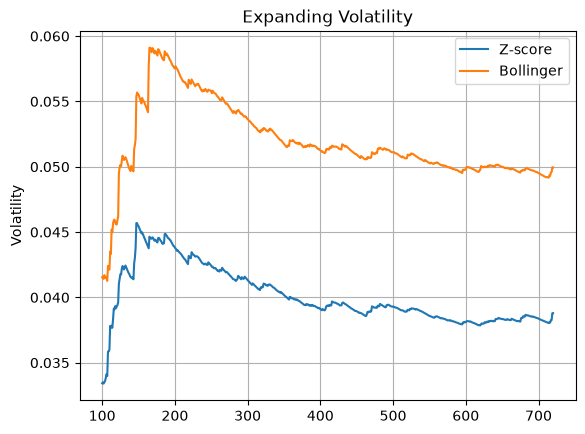

In [ ]:
plt.plot(expanding_vol_z, label="Z-score")
plt.plot(expanding_vol_bb, label="Bollinger")
plt.title("Expanding Volatility")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)

In [ ]:
rolling_vol_z = (
    z_port_ret.rolling(24).std())

rolling_vol_bb = (
    bb_port_ret.rolling(24).std())

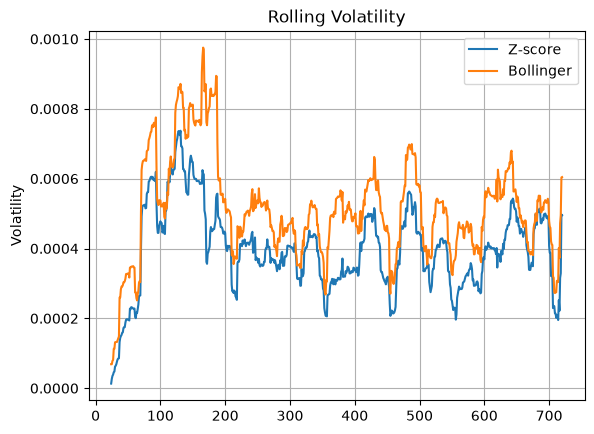

In [ ]:
plt.plot(rolling_vol_z, label="Z-score")
plt.plot(rolling_vol_bb, label="Bollinger")
plt.title("Rolling Volatility")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)

(array([ 1.,  1.,  0.,  1.,  1.,  0.,  2.,  3.,  2.,  2.,  4.,  5.,  7.,
        12., 15., 15., 31., 24., 46., 49., 52., 62., 95., 57., 55., 41.,
        37., 22., 18., 13., 12., 14.,  8.,  3.,  0.,  1.,  2.,  3.,  0.,
         1.,  0.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  1.]),
 array([-2.20443209e-03, -2.10445910e-03, -2.00448611e-03, -1.90451312e-03,
        -1.80454013e-03, -1.70456714e-03, -1.60459414e-03, -1.50462115e-03,
        -1.40464816e-03, -1.30467517e-03, -1.20470218e-03, -1.10472919e-03,
        -1.00475620e-03, -9.04783206e-04, -8.04810215e-04, -7.04837224e-04,
        -6.04864233e-04, -5.04891241e-04, -4.04918250e-04, -3.04945259e-04,
        -2.04972268e-04, -1.04999277e-04, -5.02628577e-06,  9.49467054e-05,
         1.94919696e-04,  2.94892688e-04,  3.94865679e-04,  4.94838670e-04,
         5.94811661e-04,  6.94784652e-04,  7.94757643e-04,  8.94730634e-04,
         9.94703626e-04,  1.09467662e-03,  1.19464961e-03,  1.29462260e-03,
         1.39459559e-03,  1.4945

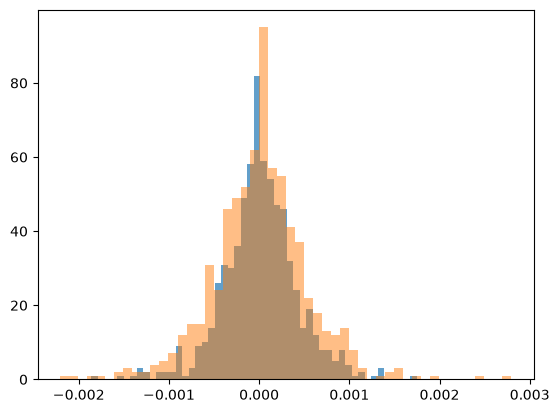

In [ ]:
plt.hist(z_port_ret, bins=50, alpha=.7)
plt.hist(bb_port_ret, bins=50, alpha=.5)

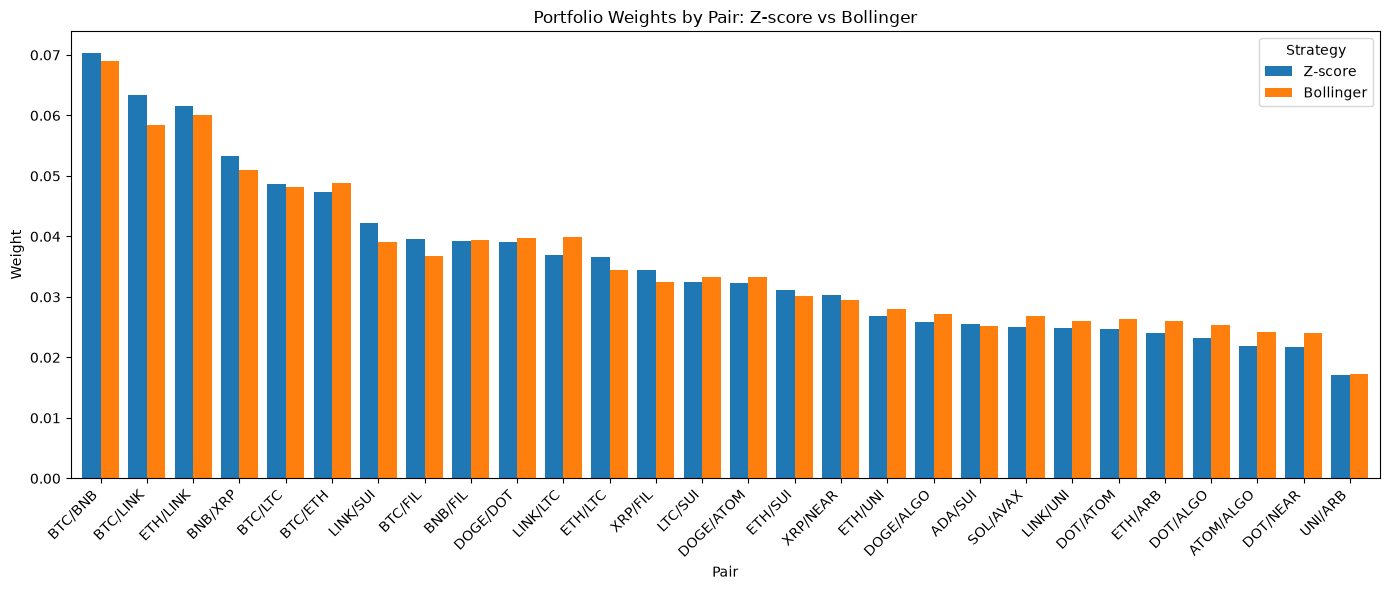

In [ ]:
weights_df = pd.concat(
    [z_weights.rename("Z-score"), bb_weights.rename("Bollinger")],
    axis=1
).fillna(0)

# Optional: sort by one of the strategies or by average weight
weights_df = weights_df.sort_values(by="Z-score", ascending=False)

# Plot side-by-side bars
ax = weights_df.plot(kind="bar", figsize=(14, 6), width=0.8)

ax.set_title("Portfolio Weights by Pair: Z-score vs Bollinger")
ax.set_xlabel("Pair")
ax.set_ylabel("Weight")
ax.legend(title="Strategy")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
pair_contribution = z_weights * z_port_ret

In [ ]:
z_port_ret

1      0.000000
2      0.000000
3      0.000000
4      0.000000
5      0.000000
         ...   
716    0.000105
717   -0.001100
718    0.000529
719   -0.001862
720   -0.000400
Length: 720, dtype: float64

In [ ]:
z_ret_dict = {}
bb_ret_dict = {}

for (a, b, strat), bt in all_backtests.items():
    pair_name = f"{a}/{b}"
    if strat == "zscore":
        z_ret_dict[pair_name] = bt["strategy_ret"]
    elif strat == "bollinger":
        bb_ret_dict[pair_name] = bt["strategy_ret"]

In [ ]:
z_contrib = z_port_ret.mul(z_weights, axis=1)
bb_contrib = bb_port_ret.mul(bb_weights, axis=1)

In [ ]:
z_pair_contrib = z_contrib.sum()
bb_pair_contrib = bb_contrib.sum()

In [ ]:
pair_contrib_df = pd.concat(
    [z_pair_contrib.rename("Z-score"), bb_pair_contrib.rename("Bollinger")],
    axis=1
).fillna(0)

In [ ]:
ax = pair_contrib_df.plot(kind="bar", figsize=(14, 6), width=0.8)
ax.set_title("Contribution by Pair: Z-score vs Bollinger")
ax.set_xlabel("Pair")
ax.set_ylabel("Total Contribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
summary = pd.DataFrame({
    "Z-score": z_metrics,
    "Bollinger": bb_metrics
}).T